# Frozen ResNet18: Grad-CAM explanations

Uses `results/resnet18_frozen/best_model.pt` and its saved test predictions to generate Grad-CAM heatmaps. Run from the project directory. Outputs go into `results/resnet18_frozen_gradcam/`.

This notebook contains heatmaps, representative overlays, and deletion/insertion analysis. Classification scores, confusion matrices, learning curves, ROC/precision-recall curves, and confidence plots belong to the frozen ResNet18 experiment and are not repeated here.

Grad-CAM runs in full precision on CPU or CUDA. No additional Grad-CAM package is needed. Heatmaps explain target-class scores, not verified disease localization or causal evidence. Overlays align with the model's resized and center-cropped input. Check `analysis_status.json` and `gradcam_index.csv` for saved heatmap completion; existing deletion/insertion results are displayed without recomputation by default.

In [ ]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
SOURCE = ROOT / 'results' / 'resnet18_frozen'
OUT = ROOT / 'results' / 'resnet18_frozen_gradcam'
OUT.mkdir(parents=True, exist_ok=True)
config = json.loads((SOURCE / 'config.json').read_text())
assert config['fine_tune_last_block'] is False
classes = config['classes']
checkpoint_path = SOURCE / 'best_model.pt'
checkpoint_sha = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()
frame = pd.read_csv(SOURCE / 'test_predictions.csv')
# Reuse class targets to choose heatmap explanations; no classification evaluation is repeated.
y_true = frame['class'].map(config['class_to_idx']).to_numpy(dtype=int)
y_pred = frame['predicted_class'].map(config['class_to_idx']).to_numpy(dtype=int)
correct = y_true == y_pred
status = dict(checkpoint_sha256=checkpoint_sha, test_images=len(frame), gradcam_status='not executed')

def save_status():
    (OUT / 'analysis_status.json').write_text(json.dumps(status, indent=2), encoding='utf-8')

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / (name + '.png'), dpi=180, bbox_inches='tight')
    plt.savefig(OUT / (name + '.pdf'), bbox_inches='tight')
    plt.show()
    plt.close()

## Load the frozen checkpoint and implement Grad-CAM

All parameters stay frozen and the model stays in evaluation mode. Input gradients enable differentiation through the frozen backbone. The target is `layer4[-1]`, the final residual block output. Gradients of a target logit are spatially averaged to weight feature channels, followed by ReLU, interpolation, and per-image normalization. A zero map is saved and flagged rather than interpreted as evidence of no disease.

In [4]:
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image, ImageOps
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model=resnet18(weights=None)
model.fc=nn.Sequential(nn.Linear(512,512),nn.ReLU(),nn.Dropout(.5),
    nn.Linear(512,256),nn.ReLU(),nn.Dropout(.4),nn.Linear(256,128),nn.ReLU(),nn.Dropout(.3),nn.Linear(128,len(classes)))
checkpoint=torch.load(checkpoint_path,map_location='cpu',weights_only=True)
assert checkpoint['class_to_idx'] == config['class_to_idx']
assert checkpoint['config'] == config
model.load_state_dict(checkpoint['model_state_dict'])
model.to(DEVICE).eval()
for parameter in model.parameters(): parameter.requires_grad_(False)
preprocess=ResNet18_Weights.IMAGENET1K_V1.transforms()

def gradcam(tensor, target):
    captured=[]
    handle=model.layer4[-1].register_forward_hook(lambda module,args,output: captured.append(output))
    try:
        with torch.enable_grad():
            x=tensor.detach().unsqueeze(0).to(DEVICE).requires_grad_(True)
            logits=model(x)
            activation=captured[0]
            gradient,=torch.autograd.grad(logits[0,target],activation)
            cam=(gradient.mean(dim=(2,3),keepdim=True)*activation).sum(1,keepdim=True).relu()
            cam=F.interpolate(cam,size=tensor.shape[-2:],mode='bilinear',align_corners=False)[0,0]
            peak=float(cam.max())
            if peak>0: cam=cam/peak
            return cam.detach().cpu().numpy(), logits.softmax(1)[0].detach().cpu().numpy(), peak
    finally:
        handle.remove()


## Save Grad-CAM results for every test image

Default: process all 584 test images with predicted-class targets; for errors, also save a true-class target map. Set `MAX_IMAGES` to an integer for a smaller deterministic run. Each PNG shows the exact RGB input crop, predicted-class overlay, and true-class overlay. Raw normalized heatmaps are stored as NumPy arrays. Representative panels select up to one correct and one incorrect example per class; these are illustrative, not a random performance sample.

C:\Users\jagje\AppData\Local\Temp\ipykernel_63900\2085424021.py:29: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  peak=float(cam.max())


Completed 25/584
Completed 50/584
Completed 75/584
Completed 100/584
Completed 125/584
Completed 150/584
Completed 175/584
Completed 200/584
Completed 225/584
Completed 250/584
Completed 275/584
Completed 300/584
Completed 325/584
Completed 350/584
Completed 375/584
Completed 400/584
Completed 425/584
Completed 450/584
Completed 475/584
Completed 500/584
Completed 525/584
Completed 550/584
Completed 575/584


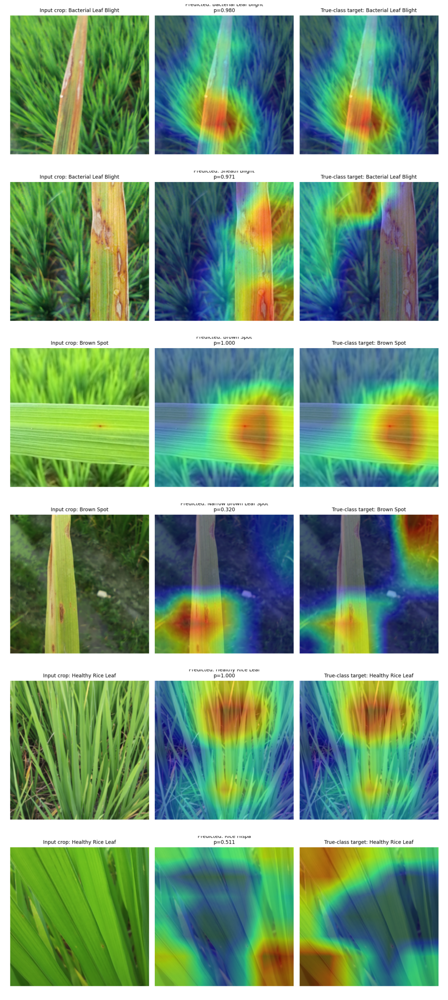

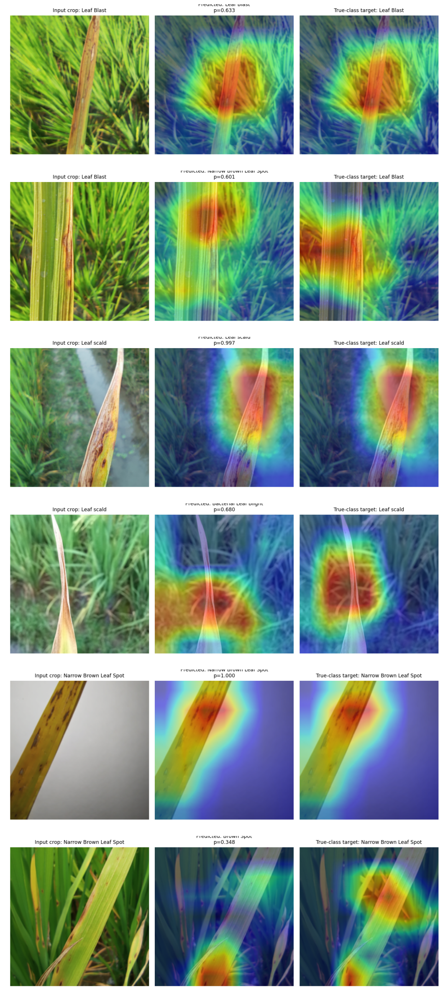

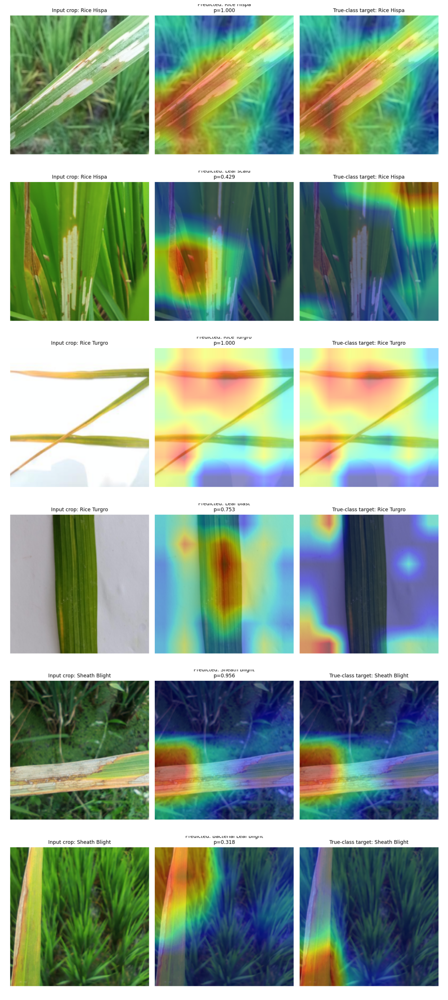

Saved results to C:\paras\Final-Year-Project\Final-Year-Project\results\resnet18_frozen_gradcam


In [5]:
MAX_IMAGES = None
CAM_DIR=OUT/'gradcam'; CAM_DIR.mkdir(exist_ok=True)
mean=np.array(preprocess.mean).reshape(3,1,1)
std=np.array(preprocess.std).reshape(3,1,1)
records=[]; representative=[]
for class_index in range(len(classes)):
    for success in [True,False]:
        candidates=np.flatnonzero((y_true==class_index)&(correct==success))
        if len(candidates): representative.append(int(candidates[0]))
status['gradcam_status']='running'; save_status()
try:
    for i,row in frame.iloc[:MAX_IMAGES].iterrows():
        path=ROOT/'split_dataset'/'test'/row['path']
        with Image.open(path) as image:
            tensor=preprocess(ImageOps.exif_transpose(image).convert('RGB'))
        rgb=np.clip((tensor.numpy()*std+mean).transpose(1,2,0),0,1)
        predicted_cam,probs,peak=gradcam(tensor,int(y_pred[i]))
        true_cam,_,true_peak=gradcam(tensor,int(y_true[i])) if y_true[i]!=y_pred[i] else (predicted_cam,probs,peak)
        stem=f'{i:04d}'
        np.savez_compressed(CAM_DIR/(stem+'.npz'),predicted_cam=predicted_cam,true_cam=true_cam)
        fig,axes=plt.subplots(1,3,figsize=(11,4))
        for ax in axes: ax.imshow(rgb); ax.axis('off')
        axes[0].set_title('Input crop: '+classes[y_true[i]],fontsize=9)
        axes[1].imshow(predicted_cam,cmap='jet',alpha=.45,vmin=0,vmax=1)
        axes[1].set_title(f'Predicted: {classes[y_pred[i]]}\np={probs[y_pred[i]]:.3f}',fontsize=9)
        axes[2].imshow(true_cam,cmap='jet',alpha=.45,vmin=0,vmax=1)
        axes[2].set_title('True-class target: '+classes[y_true[i]],fontsize=9)
        fig.tight_layout(); fig.savefig(CAM_DIR/(stem+'.png'),dpi=140); plt.close(fig)
        records.append(dict(index=i,path=row['path'],true_class=classes[y_true[i]],predicted_class=classes[y_pred[i]],confidence=float(probs.max()),correct=bool(correct[i]),predicted_cam_zero=peak==0,true_cam_zero=true_peak==0,overlay=f'gradcam/{stem}.png',heatmaps=f'gradcam/{stem}.npz'))
        if (i+1)%25==0: print(f'Completed {i+1}/{len(frame.iloc[:MAX_IMAGES])}')
    status['gradcam_status']='complete'; status['gradcam_images']=len(records)
finally:
    pd.DataFrame(records).to_csv(OUT/'gradcam_index.csv',index=False)
    status.update(device=str(DEVICE),torch_version=torch.__version__,target_layer='layer4[-1]',python=platform.python_version())
    save_status()
for group,start in enumerate(range(0,len(representative),6)):
    selected=[i for i in representative[start:start+6] if (CAM_DIR/f'{i:04d}.png').exists()]
    if not selected: continue
    fig,axes=plt.subplots(len(selected),1,figsize=(14,4*len(selected)),squeeze=False)
    for ax,i in zip(axes[:,0],selected): ax.imshow(plt.imread(CAM_DIR/f'{i:04d}.png')); ax.axis('off')
    savefig(f'gradcam_examples_{group+1}')
print('Saved results to',OUT)

## Interpretation and completion check

Read `analysis_status.json` and `gradcam_index.csv` before reporting completion. Bright regions indicate positive contributions to a class logit within this method. Inspect background attention and errors; do not treat heatmaps as segmentation masks. Grad-CAM uses a coarse final feature grid and per-image normalization, so intensity cannot be compared quantitatively across images. No model weights are modified.

## Deletion and insertion curves
Evaluate the saved predicted-class Grad-CAM maps on all 584 test images. Pixels are ranked from highest to lowest saliency, with stable ordering for ties. The target remains the original predicted class. Deletion replaces pixels with ImageNet mean RGB; insertion restores pixels from a Gaussian-blurred crop (kernel 51, sigma 20). Curves use 10% increments and trapezoidal AUC; lower deletion AUC and higher insertion AUC indicate stronger faithfulness under these baselines. Shading shows mean ? 1.96 standard errors across test images. Zero heatmaps are retained and flagged in the per-image CSV.


In [ ]:
from pathlib import Path
import hashlib
import json
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.transforms.functional import gaussian_blur
from PIL import Image, ImageOps

def plot_deletion_insertion(steps=10, threads=4):
    if steps < 2:
        raise ValueError("steps must be at least 2")
    torch.set_num_threads(threads)
    root = Path.cwd().resolve()
    source = root / 'results/resnet18_frozen'
    out = root / 'results/resnet18_frozen_gradcam'
    config = json.loads((source / 'config.json').read_text())
    checkpoint_path = source / 'best_model.pt'
    digest = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()
    status = json.loads((out / 'analysis_status.json').read_text())
    assert status['checkpoint_sha256'] == digest
    assert status['gradcam_status'] == 'complete'
    frame = pd.read_csv(source / 'test_predictions.csv')
    index = pd.read_csv(out / 'gradcam_index.csv')
    assert len(index) == len(frame) and index['path'].tolist() == frame['path'].tolist()
    with np.load(source / 'test_outputs.npz', allow_pickle=False) as cache:
        assert cache['model_sha256'].item() == digest
        saved_probabilities = cache['probabilities'].copy()
    model = resnet18(weights=None)
    model.fc = nn.Sequential(nn.Linear(512,512), nn.ReLU(), nn.Dropout(.5),
        nn.Linear(512,256), nn.ReLU(), nn.Dropout(.4), nn.Linear(256,128),
        nn.ReLU(), nn.Dropout(.3), nn.Linear(128,len(config['classes'])))
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
    assert checkpoint['config'] == config
    model.load_state_dict(checkpoint['model_state_dict'])
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device).eval()
    preprocess = ResNet18_Weights.IMAGENET1K_V1.transforms()
    fractions = np.linspace(0, 1, steps + 1)
    deletion, insertion = [], []
    started = time.perf_counter()
    with torch.inference_mode():
        for i, row in frame.iterrows():
            target = int(saved_probabilities[i].argmax())
            with Image.open(root / 'split_dataset/test' / row['path']) as image:
                original = preprocess(ImageOps.exif_transpose(image).convert('RGB'))
            with np.load(out / index.iloc[i]['heatmaps'], allow_pickle=False) as maps:
                cam = maps['predicted_cam'].copy()
            assert cam.shape == tuple(original.shape[-2:]) and np.isfinite(cam).all()
            # Stable sorting makes ties reproducible; zero maps have no meaningful ranking.
            order = np.argsort(-cam.ravel(), kind='stable')
            ranks = np.empty(order.size, dtype=np.int64)
            ranks[order] = np.arange(order.size)
            counts = np.rint(fractions * order.size).astype(np.int64)
            mask = torch.from_numpy(ranks[None, :] < counts[:, None]).reshape(-1, 1, *cam.shape)
            # Zero in normalized space is the ImageNet mean RGB color.
            deleted = torch.where(mask, torch.zeros_like(original), original)
            # Restore original pixels into a heavily blurred version of the same crop.
            baseline = gaussian_blur(original, [51, 51], [20., 20.])
            inserted = torch.where(mask, original, baseline)
            perturbed = torch.cat([deleted, inserted]).to(device)
            scores = torch.cat([model(batch).softmax(1)[:, target]
                                for batch in perturbed.split(16)]).cpu().numpy()
            d, ins = np.split(scores, 2)
            assert np.isclose(ins[-1], d[0], atol=2e-5)
            deletion.append(d)
            insertion.append(ins)
            # Save partial results so an interrupted run is still inspectable.
            if (i + 1) % 25 == 0 or i + 1 == len(frame):
                print(f'{i+1}/{len(frame)} images; elapsed {(time.perf_counter()-started)/60:.1f} min', flush=True)
                np.savez_compressed(out / 'deletion_insertion_progress.npz',
                    fractions=fractions, deletion=np.asarray(deletion), insertion=np.asarray(insertion))
    deletion, insertion = np.asarray(deletion), np.asarray(insertion)
    assert np.isfinite(deletion).all() and np.isfinite(insertion).all()
    tables = []
    summary = dict(checkpoint_sha256=digest, images=len(frame), steps=steps,
        target='original predicted class (fixed throughout perturbation)',
        ranking='saved predicted-class Grad-CAM, descending, stable tie order',
        deletion_baseline='ImageNet mean RGB',
        insertion_baseline='Gaussian blur: kernel 51, sigma 20, on 224x224 crop',
        zero_cam_images=int(index['predicted_cam_zero'].sum()), device=str(device))
    from matplotlib.figure import Figure
    from matplotlib.backends.backend_agg import FigureCanvasAgg
    fig = Figure(figsize=(12, 4.6))
    FigureCanvasAgg(fig)
    axes = fig.subplots(1, 2, sharey=True)
    for ax, values, name, direction, color in zip(axes, [deletion, insertion],
            ['Deletion', 'Insertion'], ['lower is better', 'higher is better'], ['#c44e52', '#2274a5']):
        mean = values.mean(0)
        sem = values.std(0, ddof=1) / np.sqrt(len(values))
        aucs = np.trapezoid(values, fractions, axis=1)
        summary[name.lower() + '_auc'] = float(aucs.mean())
        tables.append(pd.DataFrame(dict(curve=name.lower(), fraction=fractions,
            mean_probability=mean, standard_error=sem)))
        ax.plot(fractions * 100, mean, 'o-', color=color, lw=2,
                label=f'Mean AUC = {aucs.mean():.4f}')
        ax.fill_between(fractions * 100, np.clip(mean-1.96*sem,0,1),
                        np.clip(mean+1.96*sem,0,1), color=color, alpha=.18)
        ax.set(title=f'{name} curve ({direction})',
               xlabel=f'Pixels {"removed" if name == "Deletion" else "restored"} (%)',
               xlim=(0,100), ylim=(0,1.02))
        ax.grid(alpha=.2)
        ax.legend(loc='best')
    axes[0].set_ylabel('Probability of original predicted class')
    fig.suptitle(f'Frozen ResNet18 / Grad-CAM — {len(frame)} test images')
    fig.text(.5, .01, 'Most salient pixels first; shading: mean ± 1.96 standard errors across images', ha='center', fontsize=9)
    fig.tight_layout(rect=(0,.035,1,.95))
    for extension in ['png', 'pdf']:
        fig.savefig(out / f'deletion_insertion_curves.{extension}', dpi=220, bbox_inches='tight')
    pd.concat(tables, ignore_index=True).to_csv(out / 'deletion_insertion_curves.csv', index=False)
    per_image = index[['index','path','true_class','predicted_class','predicted_cam_zero']].copy()
    per_image['deletion_auc'] = np.trapezoid(deletion, fractions, axis=1)
    per_image['insertion_auc'] = np.trapezoid(insertion, fractions, axis=1)
    per_image.to_csv(out / 'deletion_insertion_per_image.csv', index=False)
    np.savez_compressed(out / 'deletion_insertion_scores.npz', fractions=fractions,
                        deletion=deletion, insertion=insertion, checkpoint_sha256=digest)
    (out / 'deletion_insertion_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
    print(json.dumps(summary, indent=2), flush=True)

In [ ]:
# Computation is implemented directly in the preceding notebook cell.
# Keep False to display completed results without repeating full-test inference.
RECOMPUTE_CURVES = False
if RECOMPUTE_CURVES or not (OUT / 'deletion_insertion_curves.png').exists():
    plot_deletion_insertion(steps=10, threads=4)
else:
    print('Using saved deletion/insertion curves. Set RECOMPUTE_CURVES=True to recompute.')

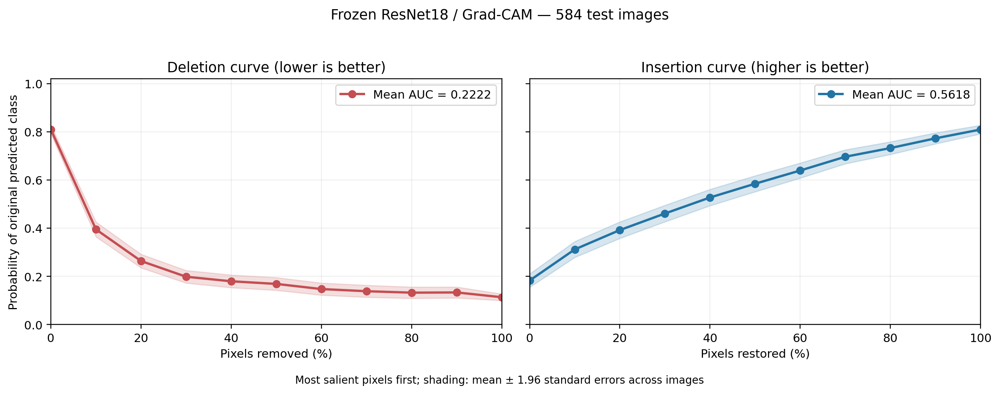

{
  "checkpoint_sha256": "6b699c9027ff322d8b46e8a8e33412f12cbef0e0c2d0c502f3914cf1f48560f7",
  "images": 584,
  "steps": 10,
  "target": "original predicted class (fixed throughout perturbation)",
  "ranking": "saved predicted-class Grad-CAM, descending, stable tie order",
  "deletion_baseline": "ImageNet mean RGB",
  "insertion_baseline": "Gaussian blur: kernel 51, sigma 20, on 224x224 crop",
  "zero_cam_images": 0,
  "device": "cpu",
  "deletion_auc": 0.22215795311339373,
  "insertion_auc": 0.5618171815532484
}


In [ ]:
from IPython.display import Image as DisplayImage
display(DisplayImage(filename=str(OUT / 'deletion_insertion_curves.png')))
display(pd.read_csv(OUT / 'deletion_insertion_per_image.csv').head())
print((OUT / 'deletion_insertion_summary.json').read_text())
